# Phase 3A: Exploratory Data Analysis (EDA) with graphs

**Goal:** look at the clean data with graphs to see *which customers churn and why*, before we prove anything with tests (that is `data_statistics.ipynb`).

**Input:** `churn_clean.csv` (made in Phase 2).

**One-line panel answer:** "EDA is where I let the data show me patterns. The graphs give me hypotheses, and the statistical tests then confirm them."

| Step | Graph | Question it answers |
|---|---|---|
| 1 | Bar chart | How many customers churn? |
| 2 | Histograms | What does each number column look like? |
| 3 | Boxplots by churn | Do churners differ from stayers on numbers? |
| 4 | Bar charts by churn | Does churn change by gender, plan, contract? |
| 5 | Churn rate by bands | At what level does the risk jump? |
| 6 | Heatmap | Which columns move together? |
| 7 | Segment heatmap | Which customer groups are riskiest? |
| 8 | Insights table | What do we tell the panel? |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Find the clean file made in Phase 2 (works from the project folder or a sub-folder)
for p in ["churn_clean.csv", "data/churn_clean.csv", "../churn_clean.csv"]:
    if os.path.exists(p):
        df = pd.read_csv(p)
        print("Loaded:", p)
        break
else:
    raise FileNotFoundError("churn_clean.csv not found. Run data_cleaning.ipynb first.")

TARGET = [c for c in df.columns if c.lower() == "churn"][0]
numeric = [c for c in df.select_dtypes(include="number").columns if c != TARGET]
categorical = df.select_dtypes(exclude="number").columns.tolist()
print("Rows, columns:", df.shape)
print("Target:", TARGET)
print("Numeric:", numeric)
print("Categorical:", categorical)

Loaded: churn_clean.csv
Rows, columns: (64374, 11)
Target: Churn
Numeric: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Categorical: ['Gender', 'Subscription Type', 'Contract Length']


## Step 1: Target distribution (churn vs stayed)

**What:** count how many customers churned and how many stayed.

**Why:** if one class is very rare (say 5% churn), accuracy becomes misleading later and we would need special handling. If the classes are balanced, we can model normally.

**How to read:** two bars; compare their heights and percentages.

       count  percent
Churn                
0      33881    52.63
1      30493    47.37


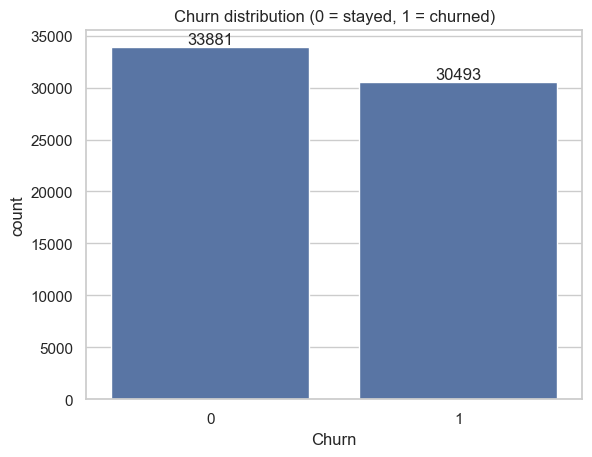

Overall churn rate: 47.37%
Balanced enough to model directly.


In [2]:
counts = df[TARGET].value_counts().sort_index()
pct = (counts / len(df) * 100).round(2)
print(pd.DataFrame({"count": counts, "percent": pct}))

ax = sns.countplot(x=TARGET, data=df)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Churn distribution (0 = stayed, 1 = churned)")
plt.show()

rate = df[TARGET].mean() * 100
print(f"Overall churn rate: {rate:.2f}%")
print("Balanced enough to model directly." if 35 <= rate <= 65 else "Imbalanced: handle with care in Phase 4.")

## Step 2: Numeric columns, histograms

**What:** a histogram shows how values are spread: bars are ranges, bar height is how many customers fall in that range.

**Why:** tells us the shape (bell-shaped, skewed, flat, several peaks). Shape decides which statistical test is fair in the next notebook.

**How to read:**
- Bell shape means roughly normal.
- Long tail on one side means skewed.
- Several peaks mean mixed groups.

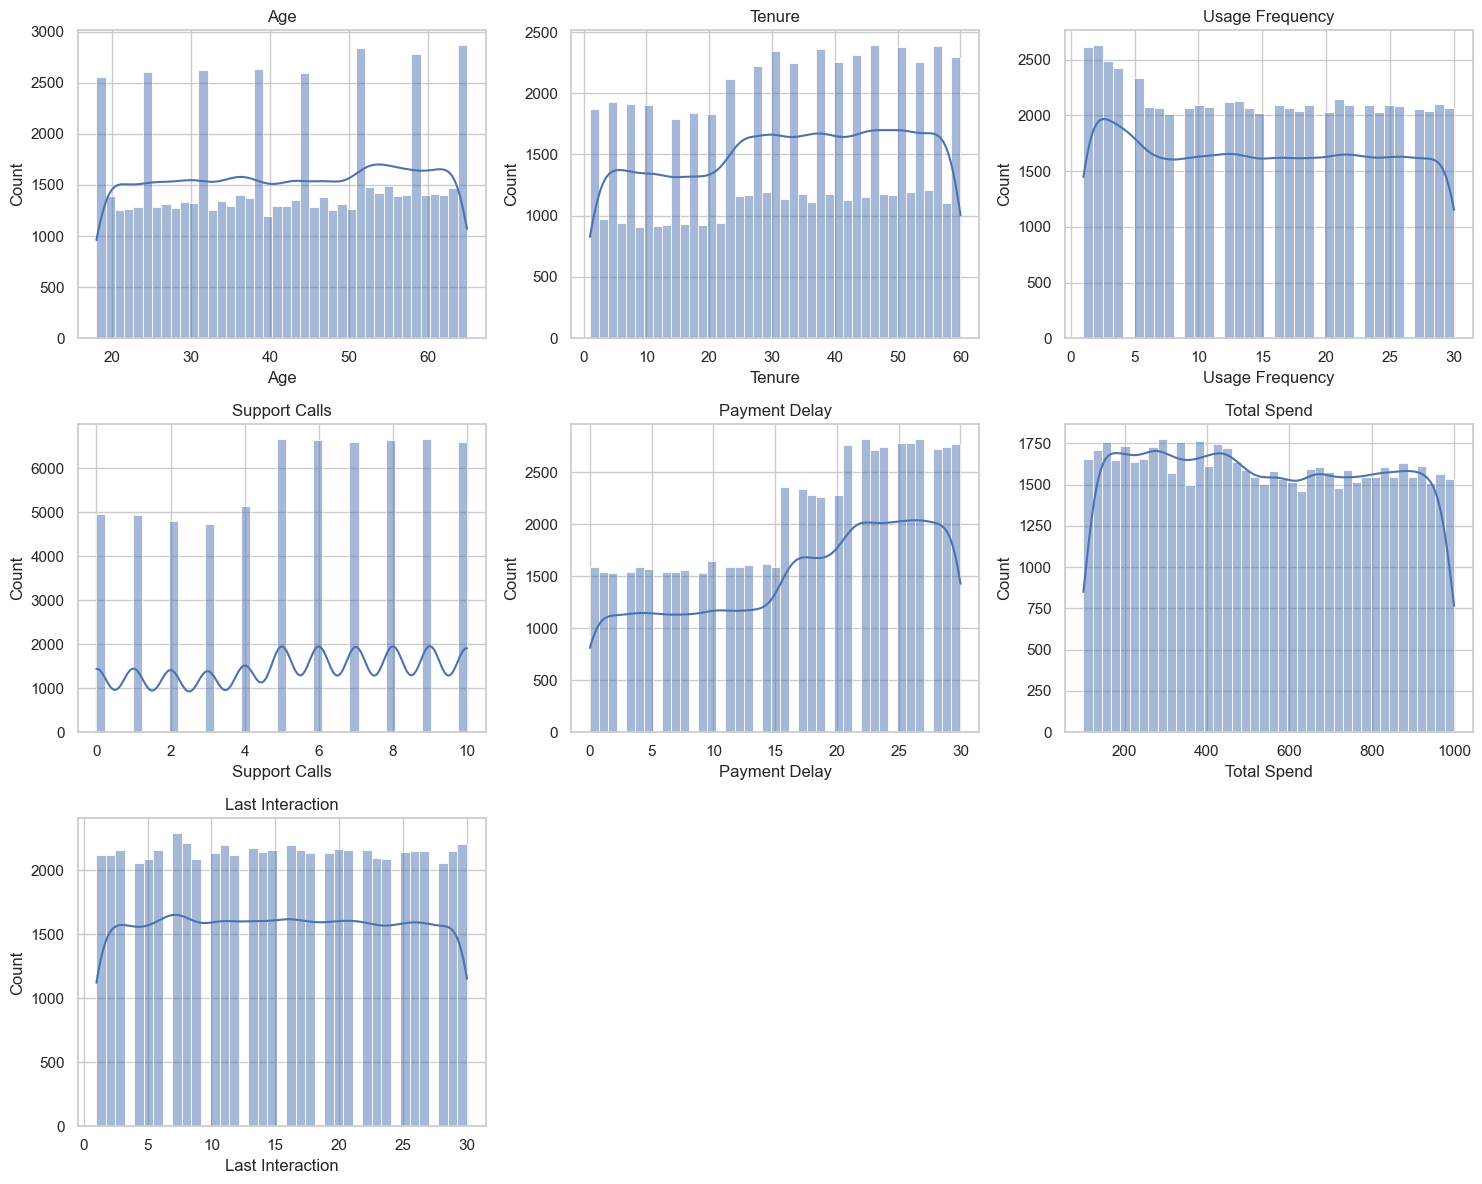

            Age    Tenure  Usage Frequency  Support Calls  Payment Delay  \
count  64374.00  64374.00         64374.00       64374.00       64374.00   
mean      41.97     31.99            15.08           5.40          17.13   
std       13.92     17.10             8.82           3.11           8.85   
min       18.00      1.00             1.00           0.00           0.00   
25%       30.00     18.00             7.00           3.00          10.00   
50%       42.00     33.00            15.00           6.00          19.00   
75%       54.00     47.00            23.00           8.00          25.00   
max       65.00     60.00            30.00          10.00          30.00   

       Total Spend  Last Interaction  
count     64374.00          64374.00  
mean        541.02             15.50  
std         260.87              8.64  
min         100.00              1.00  
25%         313.00              8.00  
50%         534.00             15.00  
75%         768.00             23.00  
max

In [3]:
n = len(numeric)
cols = 3
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, numeric):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()
print(df[numeric].describe().round(2))

## Step 3: Numeric columns split by churn (boxplots)

**What:** one boxplot per number column, with two boxes: stayed and churned.

**Why:** the core EDA question is "do churners look different?". If the two boxes sit at different heights, that column probably matters.

**How to read a boxplot:**
- The middle line is the median.
- The box holds the middle 50% of customers.
- The whiskers show the normal range; dots would be outliers.
- **Boxes that barely overlap mean a strong difference. Boxes that overlap almost fully mean a weak one.**

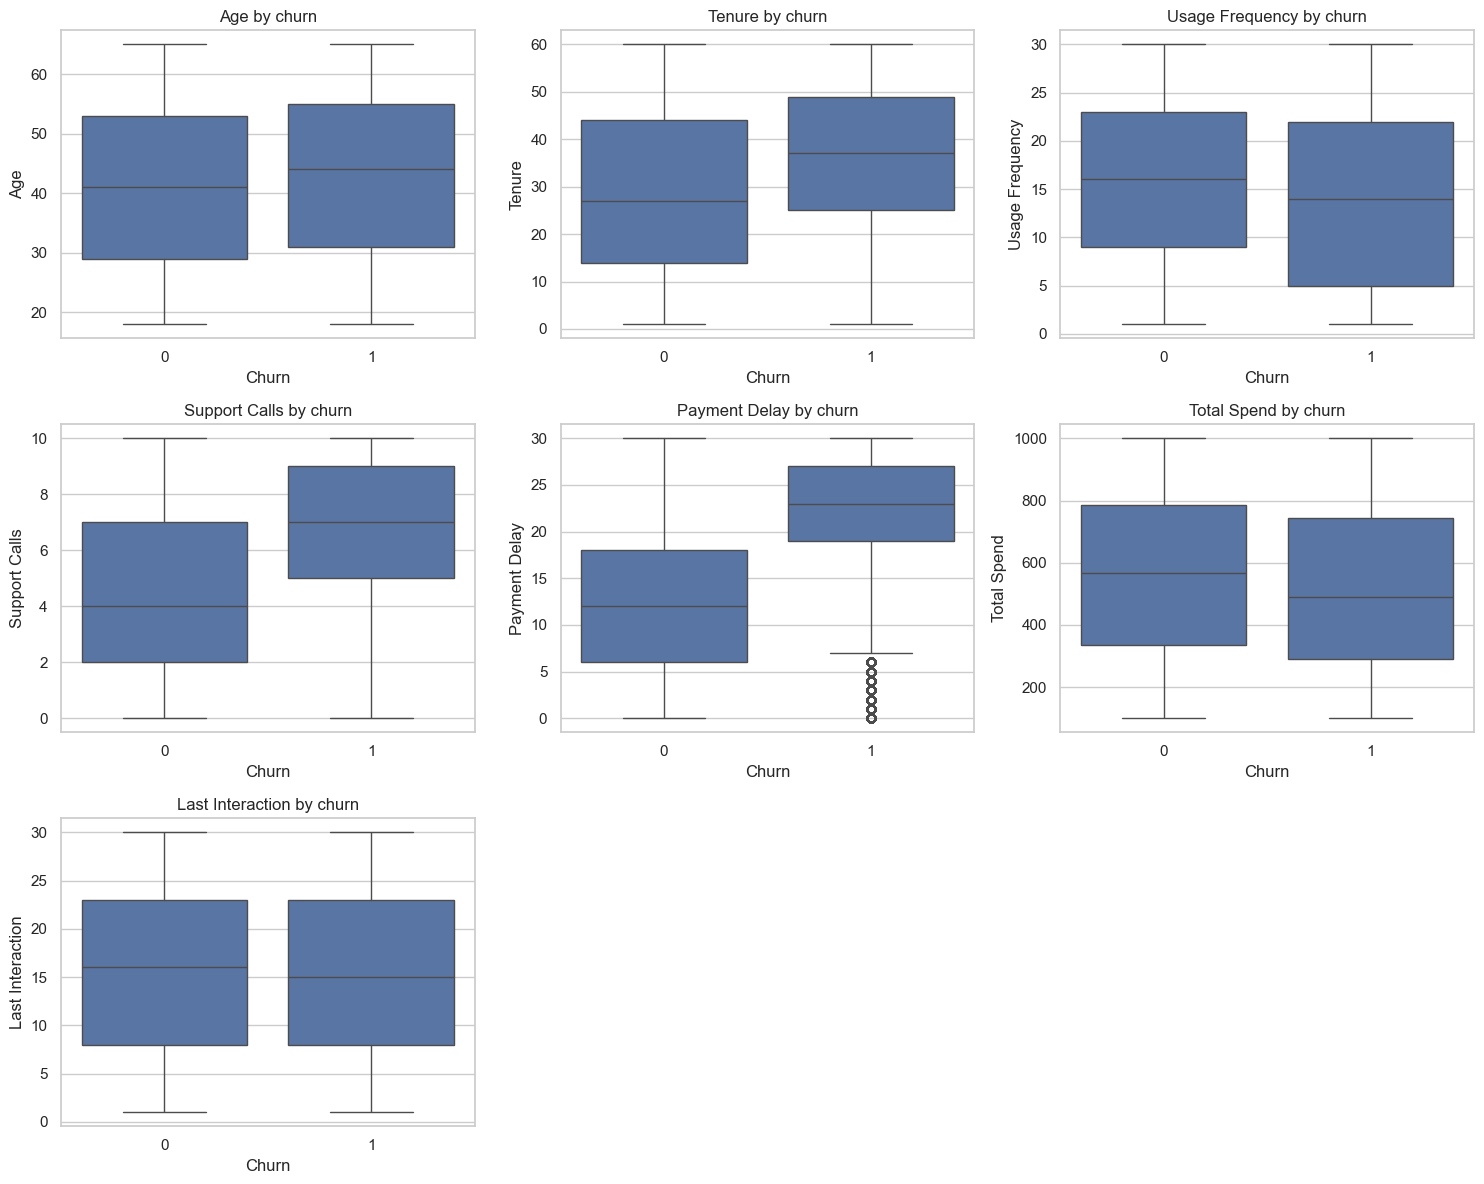

Churn                 0      1   gap
Total Spend       568.0  491.0 -77.0
Payment Delay      12.0   23.0  11.0
Tenure             27.0   37.0  10.0
Support Calls       4.0    7.0   3.0
Age                41.0   44.0   3.0
Usage Frequency    16.0   14.0  -2.0
Last Interaction   16.0   15.0  -1.0


In [4]:
n = len(numeric)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, numeric):
    sns.boxplot(x=TARGET, y=col, data=df, ax=ax)
    ax.set_title(f"{col} by churn")
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Numbers behind the picture: median per group and the gap
med = df.groupby(TARGET)[numeric].median().T
med["gap"] = med.iloc[:, 1] - med.iloc[:, 0]
print(med.round(2).sort_values("gap", key=abs, ascending=False))

## Step 4: Categorical columns vs churn

**What:** for each text column, the **churn rate** (percent who churned) inside each category.

**Why:** a raw count is misleading when groups have different sizes. A rate compares groups fairly.

**How to read:** a taller bar means that group churns more. Compare it with the overall churn rate (the dashed line).

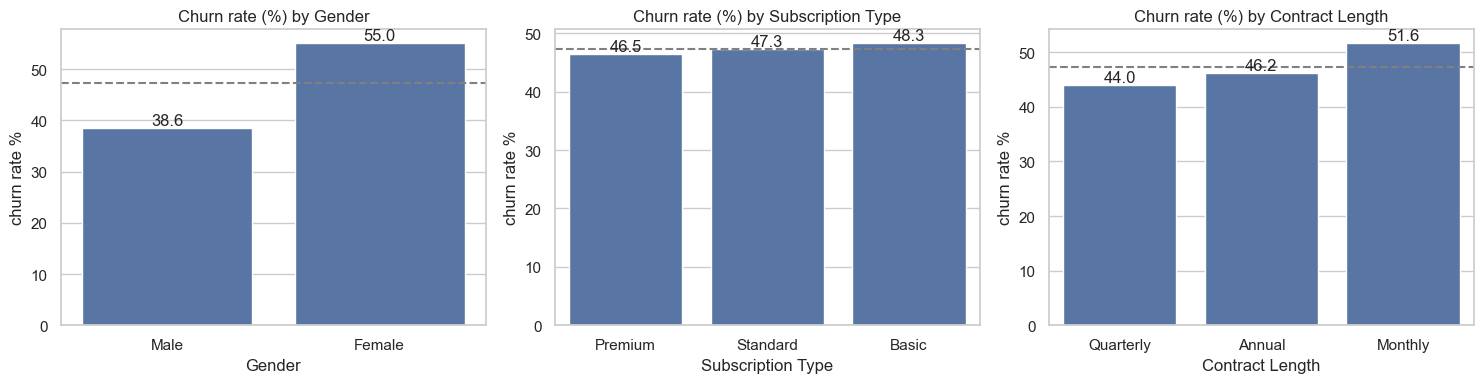

        customers  churn_rate
Gender                       
Female      34353       0.550
Male        30021       0.386 

                   customers  churn_rate
Subscription Type                       
Basic                  21451       0.483
Premium                21421       0.465
Standard               21502       0.473 

                 customers  churn_rate
Contract Length                       
Annual               21410       0.462
Monthly              22130       0.516
Quarterly            20834       0.440 



In [5]:
overall = df[TARGET].mean() * 100
fig, axes = plt.subplots(1, len(categorical), figsize=(5 * len(categorical), 4))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, categorical):
    r = df.groupby(col)[TARGET].mean().mul(100).sort_values()
    sns.barplot(x=r.index, y=r.values, ax=ax)
    ax.axhline(overall, ls="--", color="grey")
    ax.set_title(f"Churn rate (%) by {col}")
    ax.set_ylabel("churn rate %")
    for i, v in enumerate(r.values):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

for col in categorical:
    print(df.groupby(col)[TARGET].agg(customers="count", churn_rate="mean").round(3), "\n")

## Step 5: Churn rate across bands

**What:** we cut a number column into ranges (bands), for example "0-2 support calls", "3-5 calls", and compute the churn rate in each band.

**Why:** a boxplot says "different". Bands say **where the risk starts to jump**, which is a business-friendly statement ("after 4 support calls, churn doubles").

**How to read:** a line or bars that rise steadily mean more of this = more churn. A sudden jump marks a danger threshold.

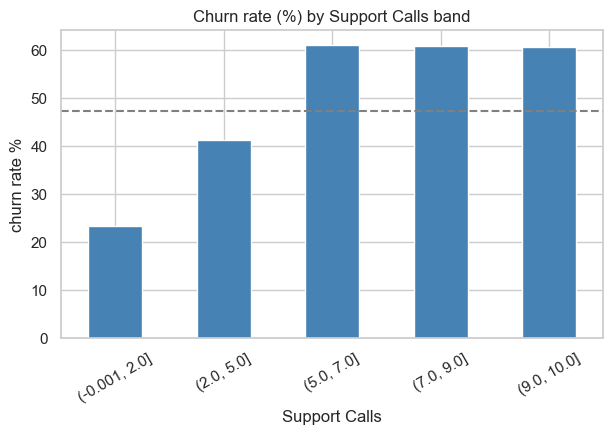

Support Calls
(-0.001, 2.0]    23.4
(2.0, 5.0]       41.4
(5.0, 7.0]       61.2
(7.0, 9.0]       60.9
(9.0, 10.0]      60.7
Name: Churn, dtype: float64 



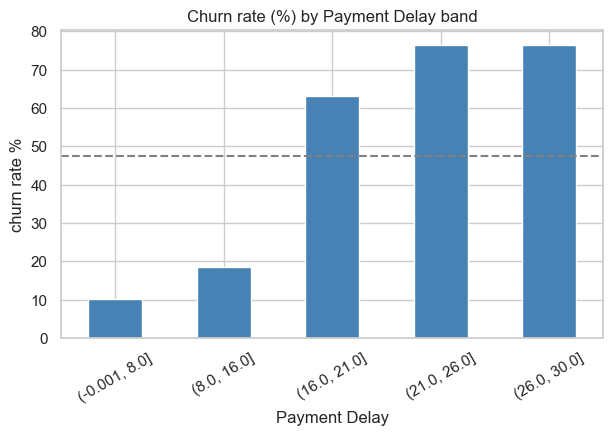

Payment Delay
(-0.001, 8.0]    10.1
(8.0, 16.0]      18.5
(16.0, 21.0]     63.0
(21.0, 26.0]     76.6
(26.0, 30.0]     76.5
Name: Churn, dtype: float64 



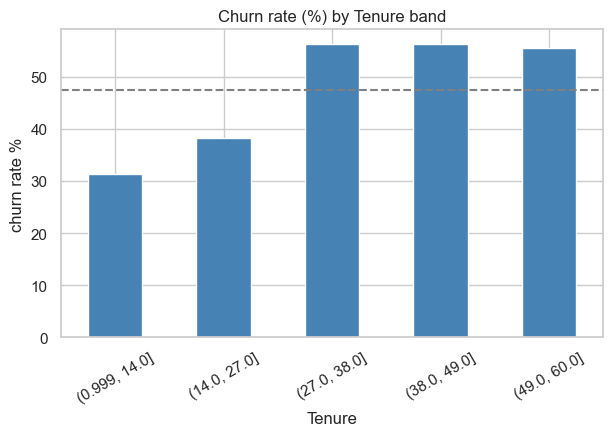

Tenure
(0.999, 14.0]    31.3
(14.0, 27.0]     38.3
(27.0, 38.0]     56.2
(38.0, 49.0]     56.2
(49.0, 60.0]     55.5
Name: Churn, dtype: float64 



In [6]:
def band_plot(col, q=5):
    if col not in df.columns:
        print(f"Column {col} not found, skipping")
        return None
    b = pd.qcut(df[col], q=q, duplicates="drop")
    r = df.groupby(b)[TARGET].mean().mul(100)
    ax = r.plot(kind="bar", color="steelblue", figsize=(7, 4))
    ax.axhline(overall, ls="--", color="grey")
    ax.set_title(f"Churn rate (%) by {col} band")
    ax.set_ylabel("churn rate %")
    plt.xticks(rotation=30)
    plt.show()
    return r.round(1)

band_cols = [c for c in ["Support Calls", "Payment Delay", "Tenure"] if c in df.columns]
for col in band_cols:
    print(band_plot(col), "\n")

## Step 6: Correlation heatmap

**What:** a grid where each cell is the correlation (from -1 to +1) between two numeric columns. We include churn as a 0/1 column.

**Why:** shows which columns move with churn, and which columns are too similar to each other (that matters for modelling).

**How to read:**
- Near +1: move up together.
- Near -1: one goes up, the other goes down.
- Near 0: no linear relation.

Rough guide: |r| below 0.1 is weak, 0.1-0.3 is mild, 0.3-0.5 is moderate, above 0.5 is strong.

**Note:** correlation shows linkage, not cause.

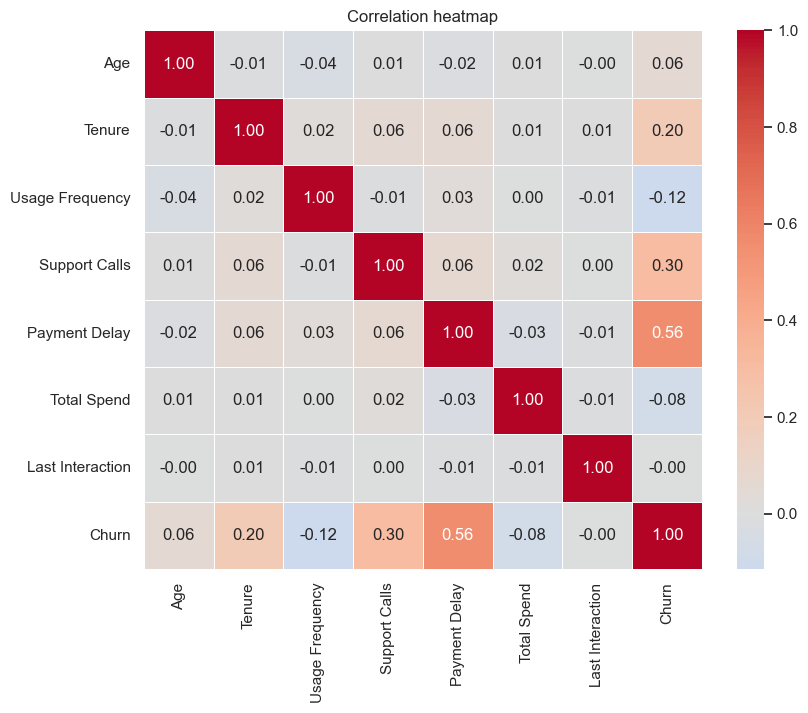

Correlation with churn (strongest first):
Payment Delay       0.557
Support Calls       0.305
Tenure              0.195
Usage Frequency    -0.115
Total Spend        -0.079
Age                 0.063
Last Interaction   -0.003
Name: Churn, dtype: float64


In [7]:
corr = df[numeric + [TARGET]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation heatmap")
plt.show()

print("Correlation with churn (strongest first):")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

## Step 7: Extra analysis, risky segments

**What:** combine two columns (contract type x subscription type) and see the churn rate for each combination. Then build a simple **risk score** from the strongest signals.

**Why:** real customers have several traits at once. Finding the worst combination is directly useful: the business can target those customers first. This is the "beyond the basics" part judges like.

**How to read the heatmap:** darker/redder cells mean a higher churn rate. Check the "customers" table too, because a very small group can look extreme by chance.

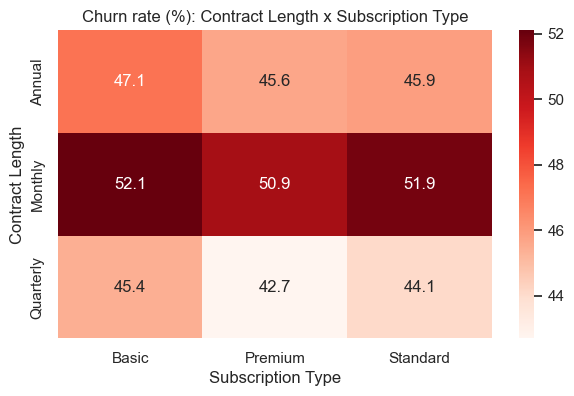

Customers in each cell:
Subscription Type  Basic  Premium  Standard
Contract Length                            
Annual              7148     7075      7187
Monthly             7373     7409      7348
Quarterly           6930     6937      6967


In [8]:
if len(categorical) >= 2:
    a, b = categorical[-1], categorical[-2]  # normally Contract Length and Subscription Type
    pivot = df.pivot_table(index=a, columns=b, values=TARGET, aggfunc="mean").mul(100)
    size = df.pivot_table(index=a, columns=b, values=TARGET, aggfunc="count")
    plt.figure(figsize=(7, 4))
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
    plt.title(f"Churn rate (%): {a} x {b}")
    plt.show()
    print("Customers in each cell:")
    print(size)

Signals used: ['Payment Delay', 'Support Calls', 'Tenure']
   customers  churn_rate
0      11180       0.122
1      25427       0.347
2      20883       0.643
3       6884       1.000


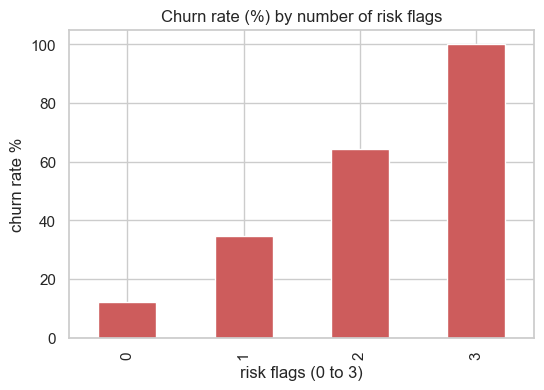

In [9]:
# Simple risk profile: flag each customer on the strongest signals found above.
# Rule: for each of the top 3 numeric signals, flag the customer if they are on the "churn-leaning" side of the median.
corr_t = df[numeric].corrwith(df[TARGET])
top = corr_t.abs().sort_values(ascending=False).head(3).index.tolist()
flags = pd.DataFrame(index=df.index)
for col in top:
    if corr_t[col] > 0:
        flags[col] = (df[col] > df[col].median()).astype(int)
    else:
        flags[col] = (df[col] < df[col].median()).astype(int)
risk_flags = flags.sum(axis=1)

print("Signals used:", top)
r = df.groupby(risk_flags)[TARGET].agg(customers="count", churn_rate="mean").round(3)
print(r)
r["churn_rate"].mul(100).plot(kind="bar", figsize=(6, 4), color="indianred")
plt.title("Churn rate (%) by number of risk flags")
plt.xlabel("risk flags (0 to 3)")
plt.ylabel("churn rate %")
plt.show()

## Step 8: Insights table (what we tell the panel)

The five hypotheses below are the standard churn questions. **Edit the wording to match the 5 hypotheses you present.**

The table fills itself from the data, so the numbers are always real. The graph only *suggests*; `data_statistics.ipynb` *proves*.

In [10]:
def num_gap(col):
    if col not in df.columns:
        return "column missing"
    m0, m1 = df[df[TARGET] == 0][col].median(), df[df[TARGET] == 1][col].median()
    return f"median stayed {m0:.1f} vs churned {m1:.1f}"

def cat_gap(col):
    if col not in df.columns:
        return "column missing"
    r = df.groupby(col)[TARGET].mean().mul(100).round(1)
    return "; ".join(f"{k}: {v}%" for k, v in r.items())

insights = pd.DataFrame({
    "Hypothesis": [
        "H1: More support calls -> higher churn",
        "H2: Longer payment delay -> higher churn",
        "H3: Short contracts (Monthly) churn more",
        "H4: Shorter tenure -> higher churn",
        "H5: Subscription type affects churn",
    ],
    "What the data shows": [
        num_gap("Support Calls"), num_gap("Payment Delay"),
        cat_gap("Contract Length"), num_gap("Tenure"), cat_gap("Subscription Type"),
    ],
})
pd.set_option("display.max_colwidth", 120)
insights

,Hypothesis,What the data shows
0,H1: More support calls -> higher churn,median stayed 4.0 vs churned 7.0
1,H2: Longer payment delay -> higher churn,median stayed 12.0 vs churned 23.0
2,H3: Short contracts (Monthly) churn more,Annual: 46.2%; Monthly: 51.6%; Quarterly: 44.0%
3,H4: Shorter tenure -> higher churn,median stayed 27.0 vs churned 37.0
4,H5: Subscription type affects churn,Basic: 48.3%; Premium: 46.5%; Standard: 47.3%


## Spoken summary (30 seconds)

"I checked the target balance first. Then I used histograms to see the shape of each column and boxplots to compare churned and retained customers. I plotted churn rate by category and by bands to find where risk jumps. The correlation heatmap showed which numbers move with churn. Finally I combined contract and subscription to find the riskiest segments, and built a simple risk-flag score. These graphs gave me five hypotheses, which I confirm with statistical tests in the next notebook."

## Likely panel questions

**Why a boxplot and not just the average?** The box shows spread and the median is not distorted by extreme values.

**Why churn *rate* and not count?** Groups have different sizes; a rate compares them fairly.

**Does correlation mean cause?** No. It shows that two things move together, not that one causes the other.

**Why bands?** They turn a number into a threshold the business can act on.

**What did you add beyond the basics?** The contract x subscription segment map and the risk-flag score.

## What we found on this dataset (use this when you explain)

- **Balance:** 52.6% stayed, 47.4% churned, so the classes are balanced and accuracy is a fair metric later.
- **Payment Delay is the strongest signal.** Churners have a median delay of 23 days vs 12 for stayers. Churn is about 10% in the lowest band and jumps to about 63% once the delay passes 16 days, then about 77% above 21 days.
- **Support Calls:** median 7 for churners vs 4 for stayers. Churn rises from 23% (0-2 calls) to about 61% (6+ calls) and then flattens.
- **Tenure goes the opposite way to what most people expect.** Churners have *longer* tenure (median 37 vs 27 months). Do not claim that new customers churn more; the data says the opposite.
- **Gender matters more than plan or contract:** Female 55.0% vs Male 38.6% churn. Subscription type is almost flat (46.5-48.3%), contract is a small effect (Monthly 51.6%, Quarterly 44.0%).
- **Contract x Subscription map is nearly uniform**, so plan and contract alone do not identify risky segments.
- **Risk flags:** customers with 0 of the 3 top flags churn 12%, with 1 flag 35%, with 2 flags 64%, with all 3 flags 100%. Mention honestly that a perfect 100% looks unusually clean, which is typical of a synthetic or heavily curated dataset.
- **Last Interaction** has no relation to churn (correlation about 0).